03 : Create a multiclass classification model to predict wine quality based on chemical properties. Dataset: Wine
Quality Dataset (UCI)

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:
df = pd.read_csv('winequality.csv')
print(df.shape)
df.head()

(6497, 13)


,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [4]:
if(df.isnull().sum().sum() > 0) :
    print("Missing Values are present :")
    print(df.isnull().sum())
else :
    print("No Missing Values found ")

Missing Values are present :
type                     0
fixed acidity           10
volatile acidity         8
citric acid              3
residual sugar           2
chlorides                2
free sulfur dioxide      0
total sulfur dioxide     0
density                  0
pH                       9
sulphates                4
alcohol                  0
quality                  0
dtype: int64


In [5]:
df.fillna(df.mean(numeric_only=True), inplace=True)
print("Missing Values Handled")

Missing Values Handled


In [6]:
df.columns

Index(['type', 'fixed acidity', 'volatile acidity', 'citric acid',
       'residual sugar', 'chlorides', 'free sulfur dioxide',
       'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol',
       'quality'],
      dtype='object')

In [7]:
x = df.drop(['type', 'quality'], axis=1)
y = df['quality']

In [8]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [9]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [15]:
li = LinearRegression()
lr = LogisticRegression(max_iter=500)
de = DecisionTreeClassifier(max_depth=10, random_state=42)
rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42) 

Linear Regression Model Training Completed !!

Prediction : [6.35180247 5.99745373 5.7545565  ... 5.57576451 5.67080999 5.43379936]

Accuracy : 53.76923076923077 %

Classification Report :
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       1.00      0.02      0.04        46
           5       0.60      0.52      0.56       420
           6       0.52      0.75      0.61       579
           7       0.48      0.20      0.28       221
           8       0.00      0.00      0.00        32

    accuracy                           0.54      1300
   macro avg       0.43      0.25      0.25      1300
weighted avg       0.54      0.54      0.50      1300



D:\Anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\Anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\Anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


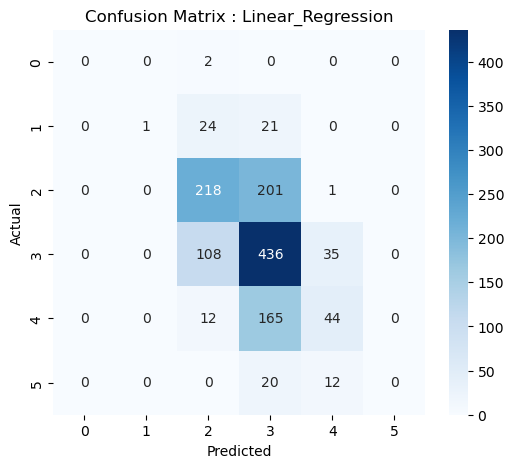

In [47]:
li.fit(x_train, y_train)
print("Linear Regression Model Training Completed !!")

li_pred = li.predict(x_test)
print("\nPrediction :", li_pred)

li_pred_class = li_pred.round().astype(int)
li_pred_class = li_pred_class.clip(y_test.min(), y_test.max())

li_acc = accuracy_score(y_test, li_pred_class)
print("\nAccuracy :", li_acc*100, "%")

li_cr = classification_report(y_test, li_pred_class)
print("\nClassification Report :\n", li_cr)

li_cm = confusion_matrix(y_test, li_pred_class)
plt.figure(figsize=(6,5))
sns.heatmap(li_cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix : Linear_Regression")
plt.show()

Logistic Regression Model Training Completed !!

Prediction : [6 6 6 ... 6 6 5]

Accuracy : 53.69230769230769 %

Classification Report :
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       1.00      0.02      0.04        46
           5       0.58      0.61      0.60       420
           6       0.52      0.69      0.59       579
           7       0.45      0.19      0.26       221
           8       0.00      0.00      0.00        32

    accuracy                           0.54      1300
   macro avg       0.42      0.25      0.25      1300
weighted avg       0.53      0.54      0.50      1300



D:\Anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\Anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\Anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


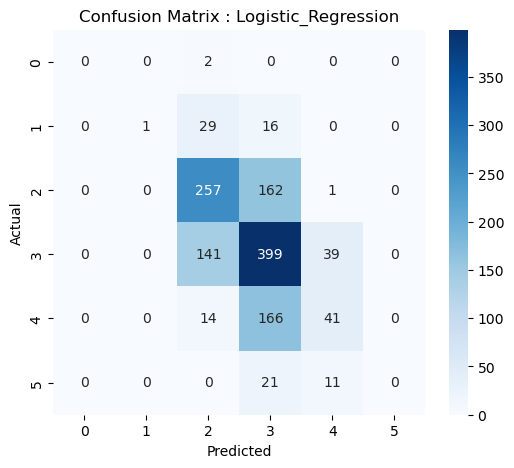

In [48]:
lr.fit(x_train, y_train)
print("Logistic Regression Model Training Completed !!")

lr_pred = lr.predict(x_test)
print("\nPrediction :", lr_pred)

lr_acc = accuracy_score(y_test, lr_pred)
print("\nAccuracy :", lr_acc*100, "%")

lr_cr = classification_report(y_test, lr_pred)
print("\nClassification Report :\n", lr_cr)

lr_cm = confusion_matrix(y_test, lr_pred)
plt.figure(figsize=(6,5))
sns.heatmap(lr_cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix : Logistic_Regression")
plt.show()

Decision Tree Model Training Completed !!

Prediction : [6 7 6 ... 5 6 5]

Accuracy : 58.15384615384615 %

Classification Report :
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.42      0.11      0.17        46
           5       0.61      0.71      0.66       420
           6       0.59      0.64      0.61       579
           7       0.50      0.36      0.42       221
           8       0.36      0.12      0.19        32

    accuracy                           0.58      1300
   macro avg       0.41      0.32      0.34      1300
weighted avg       0.57      0.58      0.57      1300



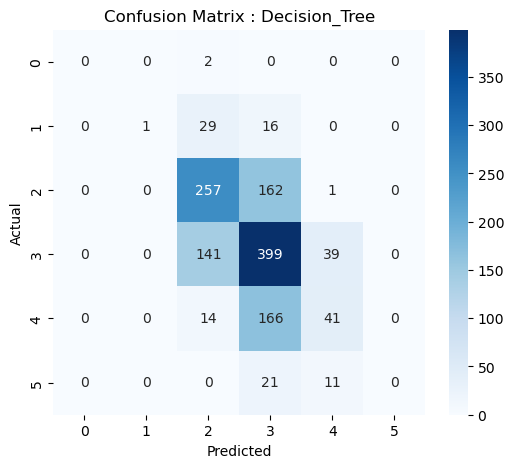

In [49]:
de.fit(x_train, y_train)
print("Decision Tree Model Training Completed !!")

de_pred = de.predict(x_test)
print("\nPrediction :", de_pred)

de_acc = accuracy_score(y_test, de_pred)
print("\nAccuracy :", de_acc*100, "%")

de_cr = classification_report(y_test, de_pred)
print("\nClassification Report :\n", de_cr)

de_cm = confusion_matrix(y_test, lr_pred)
plt.figure(figsize=(6,5))
sns.heatmap(de_cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix : Decision_Tree")
plt.show()

Random Forest Model Training Completed !!

Prediction : [6 6 6 ... 5 6 6]

Accuracy : 62.92307692307693 %

Classification Report :
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        46
           5       0.67      0.70      0.69       420
           6       0.61      0.76      0.67       579
           7       0.61      0.35      0.45       221
           8       1.00      0.09      0.17        32

    accuracy                           0.63      1300
   macro avg       0.48      0.32      0.33      1300
weighted avg       0.62      0.63      0.60      1300



D:\Anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\Anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\Anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


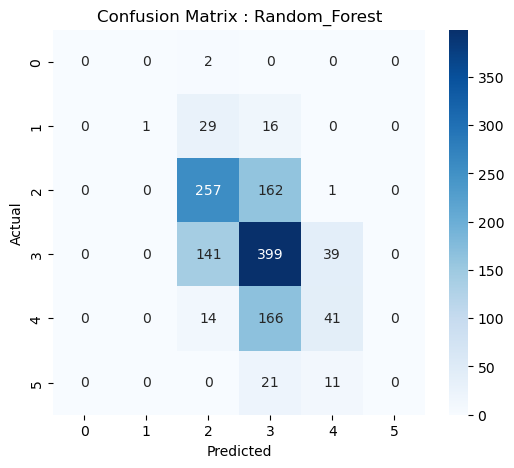

In [50]:
rf.fit(x_train, y_train)
print("Random Forest Model Training Completed !!")

rf_pred = rf.predict(x_test)
print("\nPrediction :", rf_pred)

rf_acc = accuracy_score(y_test, rf_pred)
print("\nAccuracy :", rf_acc*100, "%")

rf_cr = classification_report(y_test, rf_pred)
print("\nClassification Report :\n", rf_cr)

rf_cm = confusion_matrix(y_test, lr_pred)
plt.figure(figsize=(6,5))
sns.heatmap(rf_cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix : Random_Forest")
plt.show()

In [55]:
print("================================================")
print("               MODEL COMPARISON")
print("================================================")

comparison = pd.DataFrame({
    "Model" : [
        "Linear Regression",
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy" : [
        li_acc, lr_acc, de_acc, rf_acc
    ]
})

print(comparison)

               MODEL COMPARISON
                 Model  Accuracy
0    Linear Regression  0.537692
1  Logistic Regression  0.536923
2        Decision Tree  0.581538
3        Random Forest  0.629231


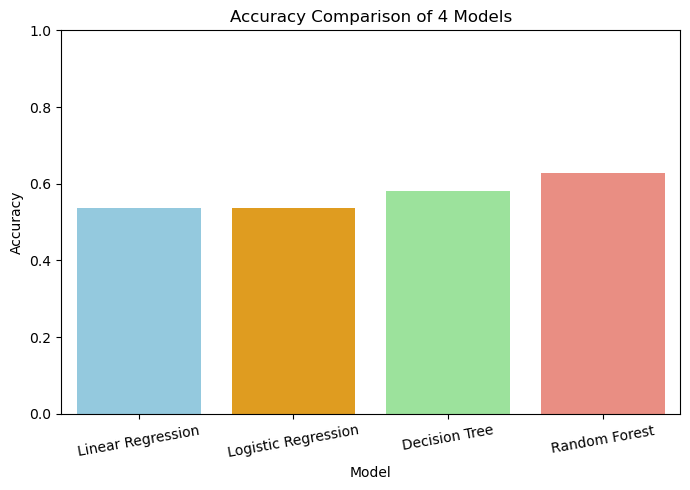

In [68]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x="Model",
    y="Accuracy",
    hue="Model",
    data=comparison,
    palette=["skyblue", "orange", "lightgreen", "salmon"],
    legend=False
)

plt.title("Accuracy Comparison of 4 Models")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [65]:
importance = pd.DataFrame({
    "Feature": x.columns,
    "Importance": rf.feature_importances_
}).sort_values(by="Importance")
print("================================================")
print(" FEATURE IMPORTANCE")
print("================================================")
print(importance)

 FEATURE IMPORTANCE
                 Feature  Importance
0          fixed acidity    0.066839
8                     pH    0.069423
2            citric acid    0.072557
5    free sulfur dioxide    0.077034
3         residual sugar    0.077706
4              chlorides    0.080363
6   total sulfur dioxide    0.080500
9              sulphates    0.081123
7                density    0.105583
1       volatile acidity    0.115683
10               alcohol    0.173188


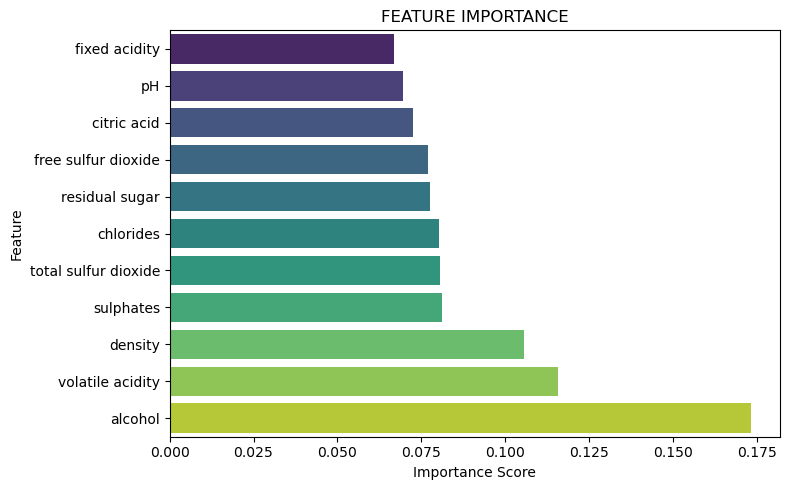

In [69]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x="Importance",
    y="Feature",
    data=importance,
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("FEATURE IMPORTANCE")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()